# Support Ticket ML Pipelines: Escalation Classification and Resolution Time Regression

**Course lab:** Leakage-safe pipelines, cross-validation and hyperparameter tuning

**Experiment A (classification):** predict whether a support ticket will be escalated (`escalated`).
**Experiment B (regression):** predict how long a ticket takes to resolve (`resolution_time_hours`).

**Main rules followed in this notebook:**
- `ticket_id` is excluded because it is only an identifier.
- The test set is held out first and used only once per experiment.
- All preprocessing is inside a Pipeline so it is fitted only on training folds.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, StratifiedKFold, KFold, cross_validate, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.metrics import classification_report, confusion_matrix, mean_absolute_error, mean_squared_error

RANDOM_STATE = 42

In [2]:
clf_df = pd.read_csv("data/classification_escalation.csv")
reg_df = pd.read_csv("data/resolution_time_regression.csv")
display(clf_df.head(), reg_df.head())

,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,escalated
0,T0000,2.0,15.0,Medium,Email,61.818896,0
1,T0001,9.0,6.0,Critical,Chat,110.024317,0
2,T0002,10.0,8.0,High,Phone,36.311244,0
3,T0003,2.0,1.0,Medium,Phone,85.127855,0
4,T0004,8.0,14.0,Medium,Chat,18.225059,0


,ticket_id,complexity_score,team_experience_years,priority,channel,customer_tenure_months,resolution_time_hours
0,R0000,7.0,10.0,Medium,Chat,32.638377,8.38724
1,R0001,4.0,15.0,Medium,Chat,45.273760,0.50000
2,R0002,4.0,13.0,Low,Portal,44.878323,0.50000
3,R0003,1.0,10.0,High,Phone,40.095034,0.50000
4,R0004,3.0,15.0,Low,Portal,47.451134,0.50000


## 1. Data Exploration

In [3]:
print("Shape:", clf_df.shape)
clf_df.info()
print("\nMissing values:")
print(clf_df.isna().sum())
print("\nTarget distribution:")
print(clf_df["escalated"].value_counts(normalize=True))

Shape: (900, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 900 entries, 0 to 899
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ticket_id               900 non-null    object 
 1   complexity_score        878 non-null    float64
 2   team_experience_years   864 non-null    float64
 3   priority                887 non-null    object 
 4   channel                 891 non-null    object 
 5   customer_tenure_months  869 non-null    float64
 6   escalated               900 non-null    int64  
dtypes: float64(3), int64(1), object(3)
memory usage: 49.3+ KB

Missing values:
ticket_id                  0
complexity_score          22
team_experience_years     36
priority                  13
channel                    9
customer_tenure_months    31
escalated                  0
dtype: int64

Target distribution:
escalated
0    0.787778
1    0.212222
Name: proportion, dtype: float64


**Classification data observations:**
- 900 tickets, 7 columns. `ticket_id` is excluded (identifier only).
- Numeric features: complexity_score, team_experience_years, customer_tenure_months.
- Categorical features: priority, channel.
- Every feature has missing values, so imputation is needed.
- The target is imbalanced (about 21% escalated), so F1 is a better metric than accuracy and the split must be stratified.

In [4]:
print("Shape:", reg_df.shape)
reg_df.info()
print("\nMissing values:")
print(reg_df.isna().sum())
print("\nTarget summary:")
print(reg_df["resolution_time_hours"].describe())

Shape: (800, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 7 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ticket_id               800 non-null    object 
 1   complexity_score        784 non-null    float64
 2   team_experience_years   776 non-null    float64
 3   priority                800 non-null    object 
 4   channel                 800 non-null    object 
 5   customer_tenure_months  780 non-null    float64
 6   resolution_time_hours   800 non-null    float64
dtypes: float64(4), object(3)
memory usage: 43.9+ KB

Missing values:
ticket_id                  0
complexity_score          16
team_experience_years     24
priority                   0
channel                    0
customer_tenure_months    20
resolution_time_hours      0
dtype: int64

Target summary:
count    800.000000
mean       5.873160
std        4.144974
min        0.500000
25%        2.631319


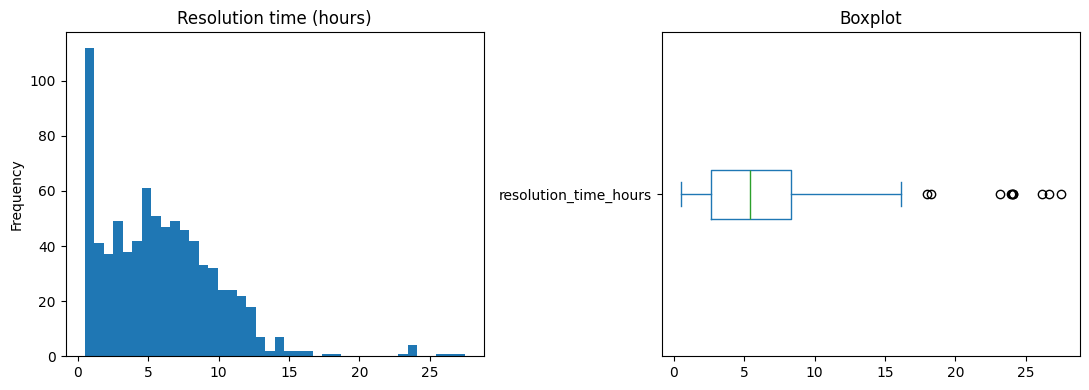

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
reg_df["resolution_time_hours"].plot(kind="hist", bins=40, ax=ax[0], title="Resolution time (hours)")
reg_df["resolution_time_hours"].plot(kind="box", vert=False, ax=ax[1], title="Boxplot")
plt.tight_layout()
plt.show()

**Regression data observations:**
- 800 tickets, same features as the classification data. Target: `resolution_time_hours`.
- Only numeric features have missing values.
- The target is right-skewed: most tickets resolve in under 11 hours, but a few take over 20. These are outliers.
- Many tickets sit exactly at 0.5 hours, which looks like a minimum cap.

## 2. Experiment A: Classification (predict `escalated`)

In [6]:
# Drop ticket_id (identifier) and separate the target
X = clf_df.drop(columns=["ticket_id", "escalated"])
y = clf_df["escalated"]

# Stratified split: the test set is held out and not touched until the end
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("\nEscalation rate (full): ", round(y.mean(), 3))
print("Escalation rate (train):", round(y_train.mean(), 3))
print("Escalation rate (test): ", round(y_test.mean(), 3))

Train: (720, 5) | Test: (180, 5)

Escalation rate (full):  0.212
Escalation rate (train): 0.212
Escalation rate (test):  0.211


In [7]:
numeric_cols = ["complexity_score", "team_experience_years", "customer_tenure_months"]
categorical_cols = ["priority", "channel"]

In [8]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer([
    ("num", numeric_pipe, numeric_cols),
    ("cat", categorical_pipe, categorical_cols),
])

preprocessor

,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,missing_values,nan
,strategy,'median'
,fill_value,None


**Split and preprocessing decisions:**
- `ticket_id` is dropped (identifier, no predictive meaning).
- 80/20 stratified split, so train and test both keep about 21% escalations.
- Numeric columns: median imputation (robust to outliers) then scaling (needed for k-NN and logistic regression).
- Categorical columns: most-frequent imputation then one-hot encoding (`handle_unknown="ignore"` avoids errors on unseen categories).
- Everything goes inside a Pipeline, so imputers, scaler and encoder are fitted only on training data.

### 2.1 Model comparison with 5-fold Stratified CV (primary metric: F1)

In [9]:
# Same folds for every model
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "k-NN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
}

fold_scores = {}
rows = []
for name, model in models.items():
    pipe = Pipeline([("prep", preprocessor), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring="f1")
    fold_scores[name] = scores["test_score"]
    rows.append({
        "Model": name,
        "Mean F1": scores["test_score"].mean(),
        "Std F1": scores["test_score"].std(),
        "Min fold": scores["test_score"].min(),
        "Max fold": scores["test_score"].max(),
    })

cv_table = pd.DataFrame(rows).sort_values("Mean F1", ascending=False).round(3)
cv_table

,Model,Mean F1,Std F1,Min fold,Max fold
0,Logistic Regression,0.393,0.063,0.326,0.511
1,k-NN,0.361,0.050,0.286,0.426
2,Decision Tree,0.331,0.058,0.230,0.400


,Logistic Regression,k-NN,Decision Tree
Fold 1,0.391,0.367,0.400
Fold 2,0.326,0.326,0.230
Fold 3,0.364,0.426,0.323
Fold 4,0.372,0.286,0.373
Fold 5,0.511,0.400,0.328


C:\Users\ruham\AppData\Local\Temp\ipykernel_5840\2344084063.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(fold_scores.values(), labels=fold_scores.keys())


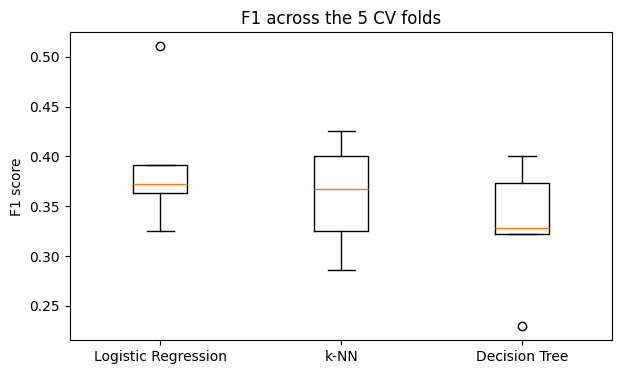

In [10]:
display(pd.DataFrame(fold_scores, index=[f"Fold {i}" for i in range(1, 6)]).round(3))

plt.figure(figsize=(7, 4))
plt.boxplot(fold_scores.values(), labels=fold_scores.keys())
plt.ylabel("F1 score")
plt.title("F1 across the 5 CV folds")
plt.show()

**CV comparison (F1, 5-fold StratifiedKFold, training set only):**
- Best mean F1: 0.393 (Logistic Regression), then k-NN 0.361, then Decision Tree 0.331.
- Most stable: k-NN (std 0.050). Least stable: Logistic Regression (std 0.063), driven by one high fold (0.511).
- Gaps between models (0.03 to 0.06) are about the size of the fold std, so the ranking is not strongly reliable.
- All scores are low. Always predicting "escalated" would give F1 ≈ 0.35 at a 21% escalation rate, so the features are only weakly predictive.
- The untuned decision tree likely overfits (no depth limit).
- Next: tune Logistic Regression (C and class_weight), since class imbalance likely hurts recall at the default 0.5 threshold.

### 2.2 Hyperparameter tuning (Logistic Regression, GridSearchCV, F1)

In [11]:
pipe_lr = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])

param_grid = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__class_weight": [None, "balanced"],
}

grid = GridSearchCV(
    pipe_lr, param_grid,
    cv=cv,              # same 5 StratifiedKFold folds as before
    scoring="f1",
    refit=True,
    n_jobs=-1,
)
grid.fit(X_train, y_train)

print("Best params:", grid.best_params_)
print("Best CV F1: ", round(grid.best_score_, 3))
print("Std at best:", round(grid.cv_results_["std_test_score"][grid.best_index_], 3))

Best params: {'model__C': 0.1, 'model__class_weight': 'balanced'}
Best CV F1:  0.52
Std at best: 0.042


In [12]:
results = pd.DataFrame(grid.cv_results_)[
    ["param_model__C", "param_model__class_weight", "mean_test_score", "std_test_score", "rank_test_score"]
].sort_values("rank_test_score")
results.round(3)

,param_model__C,param_model__class_weight,mean_test_score,std_test_score,rank_test_score
3,0.10,balanced,0.520,0.042,1
5,1.00,balanced,0.515,0.035,2
1,0.01,balanced,0.515,0.043,3
7,10.00,balanced,0.508,0.040,4
9,100.00,balanced,0.508,0.040,4
6,10.00,None,0.423,0.088,6
8,100.00,None,0.423,0.088,6
4,1.00,None,0.393,0.063,8
2,0.10,None,0.328,0.046,9
0,0.01,None,0.000,0.000,10


**Tuning decisions:**
- Candidate: Logistic Regression (best untuned mean F1).
- Search space: C in [0.01, 0.1, 1, 10, 100] and class_weight in [None, "balanced"].
- Why these: C controls regularization strength; class_weight="balanced" counters the 21% minority class.
- Search used the same 5 StratifiedKFold folds and F1 scoring, on the training set only.
- Best params: C=0.1, class_weight="balanced"; best CV F1: 0.520 (std 0.042) vs untuned 0.393 (std 0.063).
- class_weight="balanced" drove the improvement (all balanced settings: 0.508 to 0.520; unbalanced: 0.000 to 0.423). C mattered little, since the top three settings differ by 0.005, well inside the fold std.
- C=0.01 without class weighting gives F1 = 0 because the model never predicts the minority class.
- The best CV score is slightly optimistic because it is the maximum over 10 settings, so the test set gives the unbiased estimate.

### 2.3 Final evaluation on the held-out test set (run once)

In [13]:
best_clf = grid.best_estimator_

y_pred = best_clf.predict(X_test)

print(classification_report(y_test, y_pred, target_names=["Not escalated", "Escalated"]))

               precision    recall  f1-score   support

Not escalated       0.91      0.82      0.87       142
    Escalated       0.52      0.71      0.60        38

     accuracy                           0.80       180
    macro avg       0.72      0.77      0.73       180
 weighted avg       0.83      0.80      0.81       180



In [14]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

print(pd.DataFrame(cm,
    index=["Actual: Not escalated", "Actual: Escalated"],
    columns=["Pred: Not escalated", "Pred: Escalated"]))

print(f"\nTrue negatives:  {tn}")
print(f"False positives: {fp}  (predicted escalated, but was not)")
print(f"False negatives: {fn}  (predicted not escalated, but was escalated)")
print(f"True positives:  {tp}")

                       Pred: Not escalated  Pred: Escalated
Actual: Not escalated                  117               25
Actual: Escalated                       11               27

True negatives:  117
False positives: 25  (predicted escalated, but was not)
False negatives: 11  (predicted not escalated, but was escalated)
True positives:  27


**Test result (Logistic Regression, C=0.1, class_weight="balanced"):**
- Test F1 (escalated class): 0.60 vs CV F1 0.520. Precision: 0.52; Recall: 0.71. Accuracy 0.80.
- The test F1 is a bit higher than CV, but the test set has only 38 escalated tickets, so this estimate is noisy. Both numbers are well above the always-escalate baseline (F1 about 0.35).
- False positives: 25 tickets flagged for escalation that did not need it. Cost: wasted senior-agent time.
- False negatives: 11 escalated tickets we missed. Cost: serious issues left unattended, unhappy customers.
- Balanced class weights trade precision for recall: we catch 71% of escalations at the price of about half of our flags being false alarms.
- In support, missing a real escalation is usually costlier than a false alarm, so this trade-off is reasonable. If agent time were scarce, a higher decision threshold could raise precision.
- Accuracy (0.80) is misleading here because always predicting "not escalated" gives 0.79.

## 3. Experiment B: Regression (predict `resolution_time_hours`)

In [15]:
X_reg = reg_df.drop(columns=["ticket_id", "resolution_time_hours"])
y_reg = reg_df["resolution_time_hours"]

# Hold out the test set; no stratification for a continuous target
Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.2, random_state=RANDOM_STATE
)

print("Train:", Xr_train.shape, "| Test:", Xr_test.shape)
print("Mean target (train):", round(yr_train.mean(), 2))
print("Mean target (test): ", round(yr_test.mean(), 2))

Train: (640, 5) | Test: (160, 5)
Mean target (train): 5.77
Mean target (test):  6.3


In [16]:
num_cols_r = ["complexity_score", "team_experience_years", "customer_tenure_months"]
cat_cols_r = ["priority", "channel"]

preprocessor_r = ColumnTransformer([
    ("num", Pipeline([("imputer", SimpleImputer(strategy="median")),
                      ("scaler", StandardScaler())]), num_cols_r),
    ("cat", Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), cat_cols_r),
])

### 3.1 Model comparison with 5-fold CV (primary metric: MAE)

In [17]:
from sklearn.dummy import DummyRegressor

cv_r = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

reg_models = {
    "Baseline (median)": DummyRegressor(strategy="median"),
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeRegressor(random_state=RANDOM_STATE),
}

scoring = {"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"}

reg_fold_mae = {}
rows = []
for name, model in reg_models.items():
    pipe = Pipeline([("prep", preprocessor_r), ("model", model)])
    s = cross_validate(pipe, Xr_train, yr_train, cv=cv_r, scoring=scoring)
    mae = -s["test_mae"]
    rmse = -s["test_rmse"]
    reg_fold_mae[name] = mae
    rows.append({
        "Model": name,
        "Mean MAE": mae.mean(),
        "Std MAE": mae.std(),
        "Mean RMSE": rmse.mean(),
        "Std RMSE": rmse.std(),
    })

cv_table_r = pd.DataFrame(rows).sort_values("Mean MAE").round(3)
cv_table_r

,Model,Mean MAE,Std MAE,Mean RMSE,Std RMSE
2,Ridge,2.035,0.171,2.960,0.583
1,Linear Regression,2.035,0.172,2.961,0.584
0,Baseline (median),3.195,0.083,4.105,0.272
3,Decision Tree,3.269,0.144,4.679,0.540


,Baseline (median),Linear Regression,Ridge,Decision Tree
Fold 1,3.198,2.342,2.341,3.256
Fold 2,3.038,1.817,1.816,3.128
Fold 3,3.261,1.965,1.967,3.153
Fold 4,3.267,2.044,2.045,3.534
Fold 5,3.209,2.008,2.006,3.275


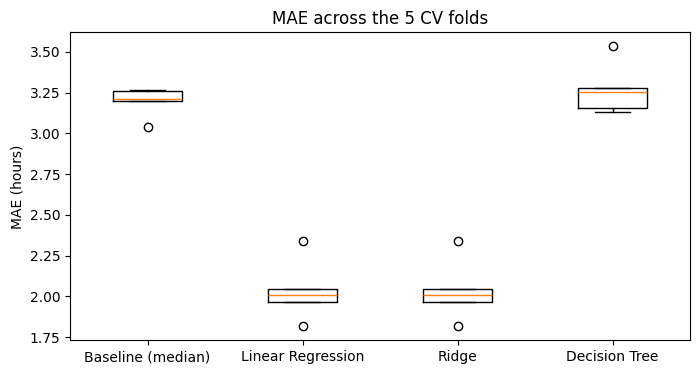

In [18]:
display(pd.DataFrame(reg_fold_mae, index=[f"Fold {i}" for i in range(1, 6)]).round(3))

plt.figure(figsize=(8, 4))
plt.boxplot(reg_fold_mae.values(), tick_labels=reg_fold_mae.keys())
plt.ylabel("MAE (hours)")
plt.title("MAE across the 5 CV folds")
plt.show()

**CV comparison (MAE, 5-fold KFold, training set only):**
- Linear Regression and Ridge (alpha=1) tie for best: MAE 2.035 (std 0.17). The median baseline scores 3.195, so the linear models cut error by about 36%.
- Ridge is almost identical to linear regression because alpha=1 is a light penalty with few features and 640 training rows.
- The untuned Decision Tree (MAE 3.269) is worse than the baseline: with no depth limit it overfits the training folds.
- The gap between linear models and baseline (about 1.16 h) is far larger than the fold std (0.17 for linear), so this ranking is reliable.
- RMSE is about 0.9 h above MAE for the linear models (2.96 vs 2.035), which shows large errors on a few tickets (the right-skewed outliers) inflate RMSE.
- Next: tune Ridge alpha (and check whether a depth-limited tree competes).